# Predicting Airline Satisfaction

In [1]:
# import required libbraries
import numpy as  np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

print("Libraries imported successfully...Bliss")

Libraries imported successfully...Bliss


In [2]:
sample_submission = "/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv"
test = "/kaggle/input/competitions/playground-series-s6e10/test.csv"
train = "/kaggle/input/competitions/playground-series-s6e10/train.csv"

df_sample = pd.read_csv(sample_submission)
df_test = pd.read_csv(test)
df_train = pd.read_csv(train)

print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df_sample.head()

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [4]:
df_test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [5]:
df_train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
print(f"sample_submission Data Shape:")
print(f"Rows: {df_sample.shape[0]} | Columns: {df_sample.shape[1]}\n")

print(f"Test Data Shape:")
print(f"Rows: {df_test.shape[0]} | Columns: {df_test.shape[1]}\n")

print(f"Train Data Shape:")
print(f"Rows: {df_train.shape[0]} | Columns: {df_train.shape[1]}")

sample_submission Data Shape:
Rows: 299844 | Columns: 2

Test Data Shape:
Rows: 299844 | Columns: 22

Train Data Shape:
Rows: 699635 | Columns: 23


In [7]:
df_sample_list = df_sample.columns.tolist()
df_train_list = df_train.columns.tolist()
df_test_list = df_test.columns.tolist()

print("df_sample_list\n", df_sample_list, "\n")
print("df_train_list\n", df_train_list, "\n")
print("df_test_list\n", df_test_list)

df_sample_list
 ['id', 'satisfaction'] 

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 

df_test_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']


In [8]:
print(df_train["satisfaction"].value_counts())
print(df_train["satisfaction"].value_counts(normalize=True).mul(100).round(2))

satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


In [9]:
## Missing values

dfs = {
    "Train" : df_train,
    "Test" : df_test
}

for name, df in dfs.items():
    print(f"Missing values in {name} Data")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("-"*50)

Missing values in Train Data
Arrival Delay in Minutes    292
dtype: int64
--------------------------------------------------
Missing values in Test Data
Arrival Delay in Minutes    130
dtype: int64
--------------------------------------------------


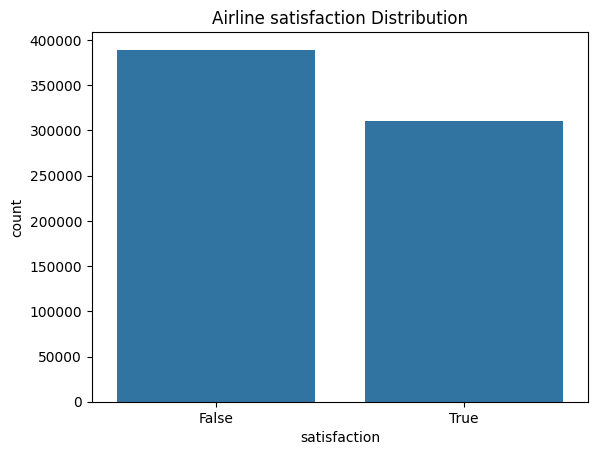

In [10]:
sns.countplot(data=df_train, x="satisfaction")
plt.title("Airline satisfaction Distribution")
plt.show()

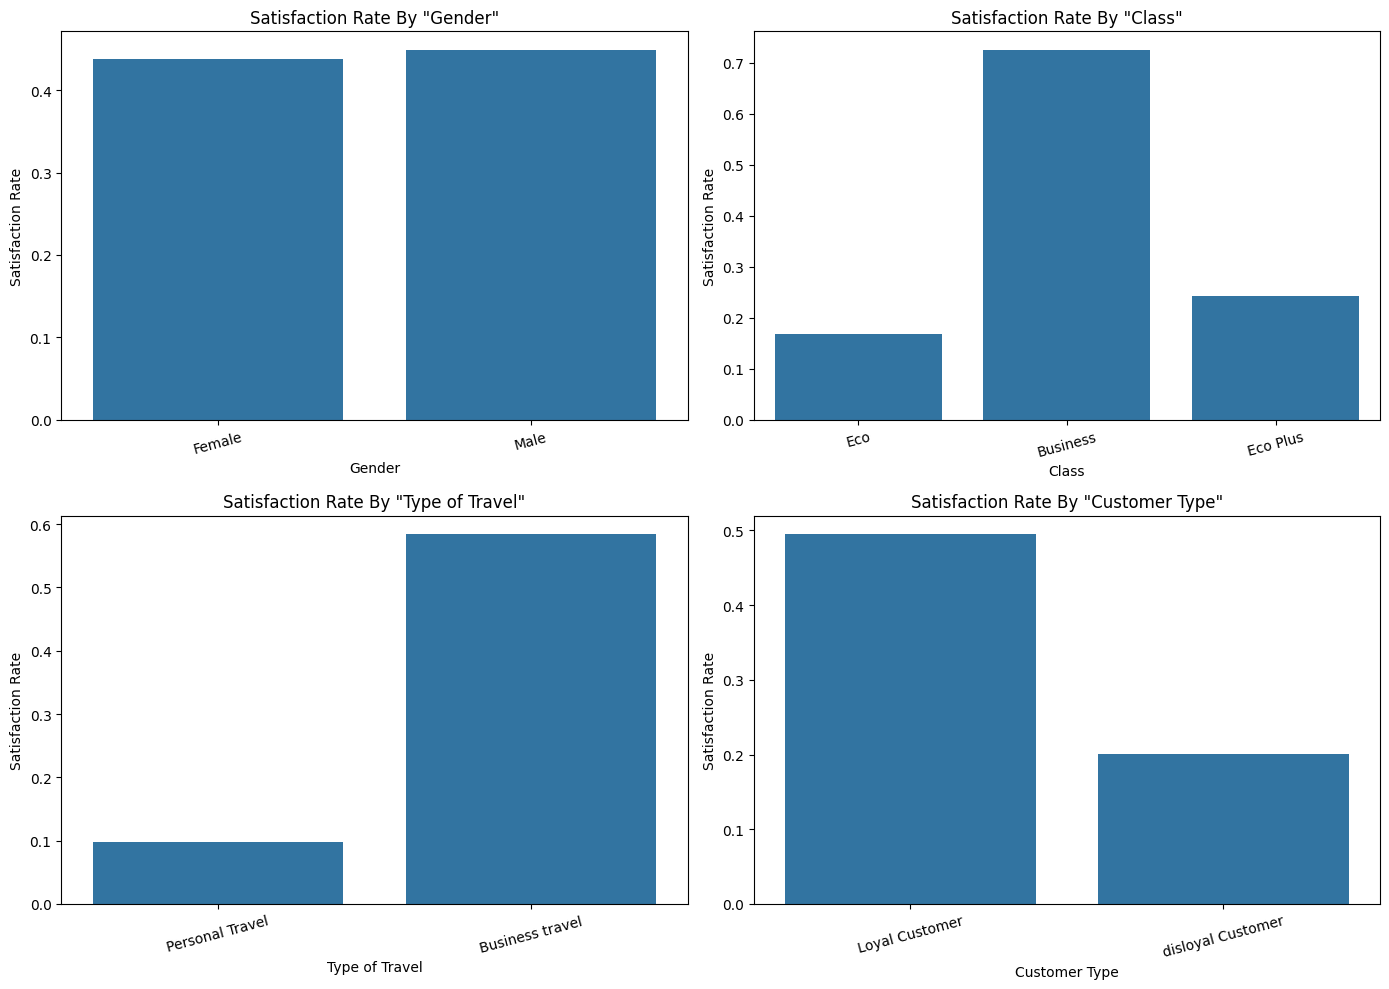

In [11]:
cat_cols = ["Gender", "Class", "Type of Travel", "Customer Type"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()  # Flatten to easily iterate through axes with a single loop

for i, col in enumerate(cat_cols):
    
    # Plot on the specific subplot axis
    sns.barplot(data=df_train, x=col, y="satisfaction", errorbar=None, ax=axes[i])
    axes[i].set_title(f"Satisfaction Rate By \"{col}\"")
    axes[i].set_ylabel("Satisfaction Rate")
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()